# Implementation and Evaluation of a NetFlow Behavioral Anomaly Detection Prototype

**CSC 786: Computer Science Problems**

**Student:** Carlos Ocasio  
**Professor:** Dr. Abid Mehmood  
**Experiment:** 72 Hour NetFlow Laboratory Experiment

## Project Overview

This notebook documents the implementation and evaluation of a NetFlow behavioral anomaly detection prototype using Isolation Forest.

The experiment uses NetFlow traffic collected during a 72 hour laboratory environment. Traffic records are processed into 1, 5, and 10 minute aggregation windows, and 12 traffic features are extracted for anomaly detection.

The objective is to evaluate how temporal aggregation affects Isolation Forest performance and examine the tradeoffs associated with different anomaly detection thresholds.

Model performance is evaluated using precision, recall, F1 score, false positive rate, and ROC AUC.

The notebook is intended to support reproducibility by allowing others to execute the analysis using the provided datasets and Python scripts.

In [ ]:
!git clone https://github.com/carlosocasio/csc786-netflow-anomaly-detection.git

fatal: destination path 'csc786-netflow-anomaly-detection' already exists and is not an empty directory.


In [ ]:
from pathlib import Path

BASE = Path("/content/csc786-netflow-anomaly-detection")
DATA = BASE / "data" / "lab_72h"
RESULTS = BASE / "results" / "lab_72h"

print("Repository exists:", BASE.exists())
print("Data directory exists:", DATA.exists())

Repository exists: True
Data directory exists: True


In [ ]:
import pandas as pd

print("Raw NetFlow:", (DATA / "netflow_72h_raw.csv.gz").exists())
print("Experiment log:", list(DATA.glob("experiment_*.csv")))

for minutes in [1, 5, 10]:
    file = DATA / f"netflow_features_{minutes}min.csv"
    df = pd.read_csv(file)

    print(f"{minutes} minute windows: {len(df)}")

Raw NetFlow: True
Experiment log: [PosixPath('/content/csc786-netflow-anomaly-detection/data/lab_72h/experiment_20261117T022817Z.csv')]
1 minute windows: 4320
5 minute windows: 864
10 minute windows: 432


In [ ]:
import gzip
import shutil

compressed = DATA / "netflow_72h_raw.csv.gz"
uncompressed = DATA / "netflow_72h_raw.csv"

with gzip.open(compressed, "rb") as source:
    with open(uncompressed, "wb") as destination:
        shutil.copyfileobj(source, destination)

print("Raw dataset exists:", uncompressed.exists())
print("Raw dataset size (MB):", round(uncompressed.stat().st_size / 1024**2, 2))

Raw dataset exists: True
Raw dataset size (MB): 149.33


In [ ]:
!python /content/csc786-netflow-anomaly-detection/scripts/analysis/feature_engineering_72h.py

Loaded 224321 client NetFlow records
Loaded 432 anomaly events
1 minute windows: 4320 records, 540 anomalous
Saved: /content/csc786-netflow-anomaly-detection/data/lab_72h/netflow_features_1min.csv
5 minute windows: 864 records, 432 anomalous
Saved: /content/csc786-netflow-anomaly-detection/data/lab_72h/netflow_features_5min.csv
10 minute windows: 432 records, 216 anomalous
Saved: /content/csc786-netflow-anomaly-detection/data/lab_72h/netflow_features_10min.csv


In [ ]:
!python /content/csc786-netflow-anomaly-detection/scripts/analysis/isolation_forest_baseline_72h.py


Isolation Forest: 1 minute aggregation
Training windows: 3020
Normal training windows used: 2643
Testing windows: 1300
True anomalies: 163
Predicted anomalies: 188

Threshold: 0.5497
Precision: 0.681
Recall: 0.785
F1 score: 0.729
False positive rate: 0.053
ROC AUC: 0.881

Confusion Matrix
True negatives: 1077
False positives: 60
False negatives: 35
True positives: 128

Saved predictions: /content/csc786-netflow-anomaly-detection/results/lab_72h/predictions_1min.csv

Isolation Forest: 5 minute aggregation
Training windows: 604
Normal training windows used: 300
Testing windows: 260
True anomalies: 128
Predicted anomalies: 128

Threshold: 0.5898
Precision: 0.992
Recall: 0.992
F1 score: 0.992
False positive rate: 0.008
ROC AUC: 0.999

Confusion Matrix
True negatives: 131
False positives: 1
False negatives: 1
True positives: 127

Saved predictions: /content/csc786-netflow-anomaly-detection/results/lab_72h/predictions_5min.csv

Isolation Forest: 10 minute aggregation
Training windows: 302
N

In [ ]:
baseline_results = pd.read_csv(RESULTS / "isolation_forest_comparison.csv")

baseline_results.round(3)

,aggregation_minutes,training_windows,normal_training_windows,testing_windows,true_anomalies,predicted_anomalies,threshold,precision,recall,f1_score,false_positive_rate,roc_auc,true_negatives,false_positives,false_negatives,true_positives
0,1,3020,2643,1300,163,188,0.550,0.681,0.785,0.729,0.053,0.881,1077,60,35,128
1,5,604,300,260,128,128,0.590,0.992,0.992,0.992,0.008,0.999,131,1,1,127
2,10,302,150,130,64,64,0.613,1.000,1.000,1.000,0.000,1.000,66,0,0,64


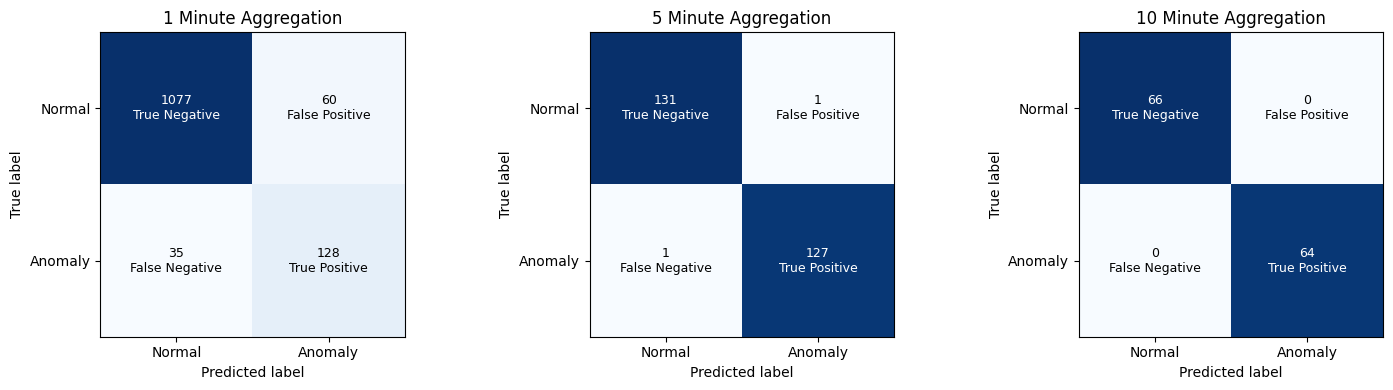

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

cell_labels = [
    ["True Negative", "False Positive"],
    ["False Negative", "True Positive"]
]

for ax, minutes in zip(axes, [1, 5, 10]):
    predictions = pd.read_csv(RESULTS / f"predictions_{minutes}min.csv")

    matrix = confusion_matrix(
        predictions["label"],
        predictions["prediction"],
        labels=[0, 1]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Normal", "Anomaly"]
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        include_values=False
    )

    for row in range(2):
        for col in range(2):
            value = matrix[row, col]
            label = cell_labels[row][col]

            color = "white" if value > matrix.max() / 2 else "black"

            ax.text(
                col, row,
                f"{value}\n{label}",
                ha="center",
                va="center",
                fontsize=9,
                color=color
            )

    ax.set_title(f"{minutes} Minute Aggregation")

plt.tight_layout()
plt.show()

In [ ]:
!python /content/csc786-netflow-anomaly-detection/scripts/analysis/isolation_forest_threshold_72h.py


1 minute aggregation
Normal training windows: 2643
Testing windows: 1300
True anomalous windows: 163
Percentile 95: Threshold=0.5497 Alerts=188 Precision=0.681 Recall=0.785 F1=0.729 FPR=0.053
Percentile 90: Threshold=0.5497 Alerts=188 Precision=0.681 Recall=0.785 F1=0.729 FPR=0.053
Percentile 85: Threshold=0.5323 Alerts=212 Precision=0.608 Recall=0.791 F1=0.688 FPR=0.073
Percentile 80: Threshold=0.5024 Alerts=272 Precision=0.482 Recall=0.804 F1=0.602 FPR=0.124
Saved scores: /content/csc786-netflow-anomaly-detection/results/lab_72h/threshold_scores_1min.csv

5 minute aggregation
Normal training windows: 300
Testing windows: 260
True anomalous windows: 128
Percentile 95: Threshold=0.6089 Alerts=117 Precision=1.000 Recall=0.914 F1=0.955 FPR=0.000
Percentile 90: Threshold=0.5898 Alerts=128 Precision=0.992 Recall=0.992 F1=0.992 FPR=0.008
Percentile 85: Threshold=0.5211 Alerts=138 Precision=0.920 Recall=0.992 F1=0.955 FPR=0.083
Percentile 80: Threshold=0.4909 Alerts=145 Precision=0.876 Reca

In [ ]:
threshold_results = pd.read_csv(RESULTS / "threshold_comparison.csv")

threshold_results.round(3)

,aggregation_minutes,percentile,threshold,training_windows,testing_windows,true_anomalies,alert_count,precision,recall,f1_score,false_positive_rate,roc_auc,true_negatives,false_positives,false_negatives,true_positives
0,1,95,0.550,2643,1300,163,188,0.681,0.785,0.729,0.053,0.881,1077,60,35,128
1,1,90,0.550,2643,1300,163,188,0.681,0.785,0.729,0.053,0.881,1077,60,35,128
2,1,85,0.532,2643,1300,163,212,0.608,0.791,0.688,0.073,0.881,1054,83,34,129
3,1,80,0.502,2643,1300,163,272,0.482,0.804,0.602,0.124,0.881,996,141,32,131
4,5,95,0.609,300,260,128,117,1.000,0.914,0.955,0.000,0.999,132,0,11,117
5,5,90,0.590,300,260,128,128,0.992,0.992,0.992,0.008,0.999,131,1,1,127
6,5,85,0.521,300,260,128,138,0.920,0.992,0.955,0.083,0.999,121,11,1,127
7,5,80,0.491,300,260,128,145,0.876,0.992,0.930,0.136,0.999,114,18,1,127
8,10,95,0.633,150,130,64,62,1.000,0.969,0.984,0.000,1.000,66,0,2,62
9,10,90,0.613,150,130,64,64,1.000,1.000,1.000,0.000,1.000,66,0,0,64


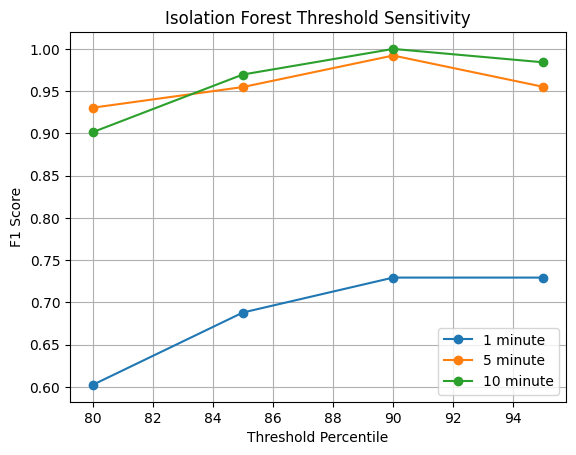

In [ ]:
import matplotlib.pyplot as plt

for minutes in [1, 5, 10]:
    data = threshold_results[
        threshold_results["aggregation_minutes"] == minutes
    ]

    plt.plot(
        data["percentile"],
        data["f1_score"],
        marker="o",
        label=f"{minutes} minute"
    )

plt.xlabel("Threshold Percentile")
plt.ylabel("F1 Score")
plt.title("Isolation Forest Threshold Sensitivity")
plt.legend()
plt.grid(True)
plt.show()

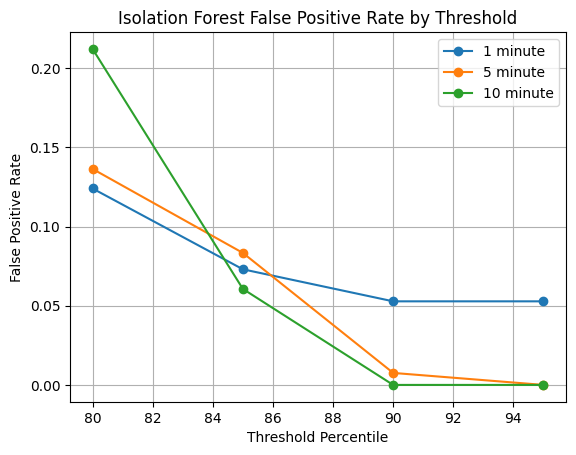

In [ ]:
for minutes in [1, 5, 10]:
    data = threshold_results[
        threshold_results["aggregation_minutes"] == minutes
    ]

    plt.plot(
        data["percentile"],
        data["false_positive_rate"],
        marker="o",
        label=f"{minutes} minute"
    )

plt.xlabel("Threshold Percentile")
plt.ylabel("False Positive Rate")
plt.title("Isolation Forest False Positive Rate by Threshold")
plt.legend()
plt.grid(True)
plt.show()

**Results and Discussion**

The 72 hour laboratory experiment evaluated Isolation Forest using NetFlow features aggregated into 1, 5, and 10 minute intervals.

At the baseline 90th percentile threshold, the 10 minute aggregation achieved the highest F1 score of 1.000, compared with 0.992 for the 5 minute interval and 0.729 for the 1 minute interval.

The threshold sensitivity evaluation showed that lowering the threshold percentile generally increased the number of alerts and false positives. For the 1 minute interval, reducing the threshold from the 95th to the 80th percentile increased the false positive rate from 0.053 to 0.124, while recall increased only slightly from 0.785 to 0.804.

The 5 minute interval achieved an F1 score of 0.992 at the 90th percentile, with a false positive rate of 0.008. The 10 minute interval achieved an F1 score of 1.000 at the 90th percentile, with no false positives or false negatives among the 130 testing windows.

For the 1 minute interval, the 90th and 95th percentile thresholds produced identical results because multiple training windows shared the same anomaly score.

**Limitations**

Although the laboratory experiment covered 72 hours of network traffic, the results were obtained in a controlled environment rather than a production network.

Longer aggregation intervals produced fewer testing observations. The 10 minute interval contained only 130 testing windows, compared with 1,300 for the 1 minute interval.

The proportion of anomalous windows also differed across aggregation intervals, which complicates direct comparisons of detection performance. Consequently, the perfect F1 score observed for the 10 minute interval should not be interpreted as evidence that this aggregation interval will consistently achieve perfect detection.

Additional experiments using different traffic patterns and longer collection periods would help determine whether these findings generalize to other network environments.